<a href="https://colab.research.google.com/github/SaraEstilaei/DigiSmart_Assistant/blob/P3%2F-Transformers/Transformers_recommendation_status_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# Part 3 — مقایسه‌ی سریع ۴ مدل Transformer برای `recommendation_status`
<div dir="rtl">


**ParsBERT / FaBERT / ParsBERT-digikala / XLM-RoBERTa base** (+ Baseline نوت‌بوک قبلی)

## دو حالت (`MODE`)
| حالت | کار | داده | زمان |
|---|---|---|---|
| `"compare"` (پیش‌فرض) | هر ۴ مدل را پشت‌سرهم آموزش می‌دهد و جدول مقایسه می‌سازد | زیرمجموعه‌ی **~۸۰۰۰ نظر** (`data_split_compare.parquet`)، ۲ epoch | حدود ۱۰ تا ۲۰ دقیقه روی T4 (وابسته به سرعت دانلود مدل‌ها) |
| `"final"` | **فقط یک مدل** (برنده) را روی کل داده آموزش می‌دهد، مدل و `predict_recommendation` را ذخیره می‌کند | `data_split_full.parquet`، ۴ epoch | بسته به مدل |

## چه چیزهایی رعایت شده؟
- **نامتعادلی کلاس‌ها:** Cross-Entropy **وزن‌دار** (`w_c = N/(K·n_c)`؛ کلاس کم‌تعداد وزن بیشتر). وزن‌ها چاپ می‌شوند، با `assert` چک می‌شوند، و یک چک روی batch واقعی ثابت می‌کند Trainer واقعاً از loss وزن‌دار استفاده می‌کند.
- **طول ورودی بدون از دست رفتن اطلاعات مهم:** `max_length` از روی توزیع طول توکن‌ها انتخاب می‌شود (پوشش ۹۸٪)، و اگر متنی بلندتر بود **برش هوشمند** انجام می‌شود: مزایا و معایب بودجه‌ی محفوظ دارند (معایب برای `not_recommended` مهم است) و از title+body هم **ابتدا و انتها** نگه داشته می‌شود، نه فقط ابتدا.
- Split یکسان برای همه‌ی مدل‌ها (از نوت‌بوک Baseline)، بدون نشت محصول/متن.
- انتخاب epoch بر اساس Macro F1 روی validation؛ مقایسه‌ی همه‌ی مدل‌ها با argmax ساده (بدون تنظیم bias) تا عادلانه باشد.
- بعد از هر مدل حافظه‌ی GPU آزاد می‌شود؛ خطای یک مدل (مثلاً اسم اشتباه) بقیه را متوقف نمی‌کند؛ در صورت OOM یک‌بار با batch نصف تکرار می‌شود.



<div dir="rtl">

## ۰) تنظیمات

In [2]:
import os, sys, re, json, time, random, warnings, inspect, math, importlib, gc, shutil, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    display = print
warnings.filterwarnings("ignore", category=FutureWarning)

MODE = "compare"                 # "compare" (4 models, small data) | "final" (ONE model, full data)
FINAL_MODEL_KEY = "parsbert"     # used only when MODE == "final": parsbert | fabert | parsbert_digikala | xlmr
COMPARE_MODEL_KEYS = ["parsbert", "fabert", "parsbert_digikala", "xlmr"]   # order = fastest/smallest first
USE_LORA = False                 # True => LoRA instead of full fine-tuning (applies to every run in this notebook)
SMOKE_TEST = False               # True => ~1 minute pipeline check on a tiny slice (first model only, results kept separately)

COMPARE_EPOCHS = 2               # 1 or 2 is enough for a screening comparison
FINAL_EPOCHS = 4
COMPARE_BS = 16                  # more optimizer steps on small data; automatically halved once if the GPU runs out of memory
FINAL_BS = 32
TIME_BUDGET_MIN = None           # e.g. 20 => stop starting new models when the next one would not fit the budget (None = no limit)

CLASS_WEIGHT_MODE = "balanced"   # "balanced" (n / (K * n_c)) | "sqrt" (softer) | "none"
MAX_LEN_CAP = 256                # upper bound for max_length
MAX_LEN_COVERAGE = 0.98          # smallest max_length that fits this share of texts untruncated
MAX_LEN_FIXED = None             # e.g. 256 to force a value
BIAS_MIN_GAIN = None if MODE == "compare" else 0.005    # post-hoc class-bias tuning (off for the noisy small comparison)
SEED = 42
N_BOOT = 1000
SAVE_FINAL_MODEL = True          # MODE == "final": save model + tokenizer + predict_recommendation

MODELS = {
    "parsbert":          {"id": "HooshvareLab/bert-fa-base-uncased",                    "lr_compare": 3e-5, "lr_final": 2e-5, "reinit_head": False},
    "fabert":            {"id": "sbunlp/fabert",                                        "lr_compare": 3e-5, "lr_final": 2e-5, "reinit_head": False},
    "parsbert_digikala": {"id": "HooshvareLab/bert-fa-base-uncased-sentiment-digikala", "lr_compare": 3e-5, "lr_final": 2e-5, "reinit_head": True},
    "xlmr":              {"id": "FacebookAI/xlm-roberta-base",                          "lr_compare": 2e-5, "lr_final": 2e-5, "reinit_head": False},
}
LORA_CFG = {"r": 16, "alpha": 32, "dropout": 0.1, "target_modules": ["query", "value"], "lr": 2e-4}

LABELS = ["recommended", "not_recommended", "no_idea"]      # SAME order as the baseline notebook
L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}
assert MODE in ("compare", "final")
assert all(k in MODELS for k in COMPARE_MODEL_KEYS + [FINAL_MODEL_KEY])

SPLIT_NAME = "compare" if MODE == "compare" else "full"
EPOCHS = 1 if SMOKE_TEST else (COMPARE_EPOCHS if MODE == "compare" else FINAL_EPOCHS)
BATCH_SIZE = COMPARE_BS if MODE == "compare" else FINAL_BS

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASELINE_WORK_DIR = Path("/content/drive/MyDrive/QBC13_final/part3_classifier")   # same as the baseline notebook
    CKPT_ROOT = Path("/content/ckpt")                                                  # fast local disk for checkpoints
else:
    BASELINE_WORK_DIR = Path("qbc13_part3")
    CKPT_ROOT = Path("ckpt_tmp")

SPLIT_PATH = BASELINE_WORK_DIR / "splits" / f"data_split_{SPLIT_NAME}.parquet"
BASELINE_OUT = BASELINE_WORK_DIR / f"outputs_{SPLIT_NAME}"
SRC_DIR = BASELINE_WORK_DIR / "src"
TF_DIR = BASELINE_WORK_DIR / "transformers"
SUFFIX = "smoke" if SMOKE_TEST else SPLIT_NAME
RESULTS_DIR, PRED_DIR = TF_DIR / f"results_{SUFFIX}", TF_DIR / f"preds_{SUFFIX}"
MODELS_OUT, FIG_DIR = TF_DIR / "models", TF_DIR / f"figures_{SUFFIX}"
for d in (RESULTS_DIR, PRED_DIR, MODELS_OUT, FIG_DIR, CKPT_ROOT, SRC_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"MODE={MODE} | split={SPLIT_NAME} | epochs={EPOCHS} | batch={BATCH_SIZE} | lora={USE_LORA} | smoke={SMOKE_TEST}")
print("models:", COMPARE_MODEL_KEYS if MODE == "compare" else [FINAL_MODEL_KEY])
print("split file:", SPLIT_PATH.resolve(), "| exists:", SPLIT_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODE=compare | split=compare | epochs=2 | batch=16 | lora=False | smoke=False
models: ['parsbert', 'fabert', 'parsbert_digikala', 'xlmr']
split file: /content/drive/MyDrive/QBC13_final/part3_classifier/splits/data_split_compare.parquet | exists: True


In [3]:
import torch
import torch.nn.functional as F
import transformers
from transformers import (AutoTokenizer, AutoConfig, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, EarlyStoppingCallback, set_seed)

if USE_LORA:
    try:
        import peft
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "peft"])
        import peft
    from peft import LoraConfig, get_peft_model, TaskType

HAS_CUDA = torch.cuda.is_available()
USE_BF16 = HAS_CUDA and torch.cuda.is_bf16_supported()
USE_FP16 = HAS_CUDA and not USE_BF16
if HAS_CUDA:
    torch.backends.cuda.matmul.allow_tf32 = True
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("CUDA:", HAS_CUDA, "|", torch.cuda.get_device_name(0) if HAS_CUDA else "NO GPU", "| bf16:", USE_BF16, "| fp16:", USE_FP16)
if not HAS_CUDA and not SMOKE_TEST:
    print("\n!!! WARNING: no GPU detected -> this will take hours. Runtime -> Change runtime type -> T4 GPU, then restart.")

torch 2.14.1+cu130 | transformers 5.22.1
CUDA: True | Tesla T4 | bf16: True | fp16: False


<div dir="rtl">


## ۱) برش هوشمند طول (ماژول `smart_truncate.py`)
این سلول فایل را در `src/` می‌نویسد (تابع پیش‌بینی نهایی هم از همین استفاده می‌کند تا آموزش و استنتاج یکسان باشند).

In [4]:
SMART_SRC = r'''
"""smart_truncate.py - length control that does not throw away the most informative parts of a review.

The classifier input is built as:  "<title> . <body> . مزایا: <advantages> . معایب: <disadvantages>"
A plain `truncation=True` cuts the END of the string, i.e. exactly the disadvantages (very informative for
`not_recommended`). Here, when a text is longer than max_len tokens:
  * advantages and disadvantages get a protected token budget (they are short and dense),
  * the title+body part keeps its beginning AND its end (head + tail), the middle is replaced by " ... ",
  * texts that already fit are returned unchanged.
Everything is done on the ORIGINAL characters (via tokenizer offsets), so no text is rewritten or decoded.
"""
import re
from typing import Dict, List, Tuple

_SEC = re.compile(r"^(.*?)(?: \. مزایا: (.*?))?(?: \. معایب: (.*))?$", re.S)
ADV_MARK = " . مزایا: "
DIS_MARK = " . معایب: "
ELL = " ... "


def split_sections(text: str) -> Tuple[str, str, str]:
    m = _SEC.match(text)
    if m is None:
        return text, None, None
    return m.group(1) or "", m.group(2), m.group(3)


def _offsets(tok, texts: List[str]):
    if not texts:
        return []
    return tok(texts, add_special_tokens=False, return_offsets_mapping=True)["offset_mapping"]


def smart_truncate_texts(texts: List[str], tok, max_len: int, adv_frac: float = 0.20, dis_frac: float = 0.30,
                         tail_frac: float = 0.30) -> Tuple[List[str], Dict[str, float]]:
    assert tok.is_fast, "a fast tokenizer is required (offset mapping)"
    usable = max_len - tok.num_special_tokens_to_add(pair=False)
    ntok = lambda s: len(tok(s, add_special_tokens=False)["input_ids"])
    m_adv, m_dis, m_ell = ntok(ADV_MARK.strip()), ntok(DIS_MARK.strip()), ntok(ELL.strip())

    secs = [split_sections(t) for t in texts]
    heads = [s[0] for s in secs]
    advs = [s[1] or "" for s in secs]
    diss = [s[2] or "" for s in secs]
    oh, oa, od = _offsets(tok, heads), _offsets(tok, advs), _offsets(tok, diss)

    out: List[str] = []
    n_trunc = lost_tokens = total_tokens_trunc = 0
    n_with_dis = n_dis_cut = 0
    for i, t in enumerate(texts):
        lh, la, ld = len(oh[i]), len(oa[i]), len(od[i])
        has_a, has_d = la > 0, ld > 0
        markers = (m_adv if has_a else 0) + (m_dis if has_d else 0)
        total = lh + la + ld + markers
        if has_d:
            n_with_dis += 1
        if total <= usable:
            out.append(t)
            continue
        avail = max(1, usable - markers)
        a_k = min(la, int(adv_frac * avail))
        d_k = min(ld, int(dis_frac * avail))
        h_k = min(lh, max(0, avail - a_k - d_k))
        left = avail - (a_k + d_k + h_k)                     # head shorter than its share -> give the rest to dis, then adv
        extra = min(left, ld - d_k); d_k += extra; left -= extra
        extra = min(left, la - a_k); a_k += extra

        head_t = heads[i]
        if h_k < lh:
            keep = h_k - m_ell
            if keep <= 1:
                head_t = heads[i][: oh[i][h_k - 1][1]] if h_k > 0 else ""
            else:
                k2 = int(keep * tail_frac)
                k1 = keep - k2
                head_t = heads[i][: oh[i][k1 - 1][1]] + ELL.rstrip() + " " + (heads[i][oh[i][lh - k2][0]:] if k2 > 0 else "")
                head_t = head_t.strip()
        adv_t = advs[i][: oa[i][a_k - 1][1]] if (a_k > 0 and a_k < la) else (advs[i] if a_k >= la else "")
        dis_t = diss[i][: od[i][d_k - 1][1]] if (d_k > 0 and d_k < ld) else (diss[i] if d_k >= ld else "")
        if has_d and d_k < ld:
            n_dis_cut += 1
        new = head_t
        if adv_t.strip():
            new += ADV_MARK + adv_t
        if dis_t.strip():
            new += DIS_MARK + dis_t
        out.append(new)
        n_trunc += 1
        kept = h_k + a_k + d_k
        lost_tokens += max(0, (lh + la + ld) - kept)
        total_tokens_trunc += lh + la + ld

    stats = {
        "n": len(texts), "n_truncated": n_trunc, "share_truncated": n_trunc / max(1, len(texts)),
        "tokens_lost_share_in_truncated": lost_tokens / max(1, total_tokens_trunc),
        "n_with_disadvantages": n_with_dis, "share_disadvantages_cut": n_dis_cut / max(1, n_with_dis),
        "usable_tokens": usable,
    }
    return out, stats

'''

(SRC_DIR / "smart_truncate.py").write_text(SMART_SRC, encoding="utf-8")
if str(SRC_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(SRC_DIR.resolve()))
import smart_truncate
importlib.reload(smart_truncate)
from smart_truncate import smart_truncate_texts
print("smart_truncate.py written ->", SRC_DIR / "smart_truncate.py")

smart_truncate.py written -> /content/drive/MyDrive/QBC13_final/part3_classifier/src/smart_truncate.py


<div dir="rtl">

## ۲) بارگذاری داده و بررسی سلامت

In [5]:
assert SPLIT_PATH.exists(), f"Run the baseline notebook first (it creates {SPLIT_PATH.name}): {SPLIT_PATH} not found"
data = pd.read_parquet(SPLIT_PATH)
need = {"id", "product_id", "split", "label", "text"}
assert need <= set(data.columns), f"missing columns: {need - set(data.columns)}"
assert set(data["split"].unique()) == {"train", "val", "test"}
assert set(data["label"].unique()) == set(LABELS), f"unexpected labels: {data['label'].unique()}"
assert data["id"].is_unique
assert data["text"].map(lambda s: isinstance(s, str) and len(s) > 0).all(), "empty/non-string text found"

P = {s: set(data.loc[data.split == s, "product_id"]) for s in ("train", "val", "test")}
T = {s: set(data.loc[data.split == s, "text"]) for s in ("train", "val", "test")}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), "product leakage"
assert not (T["train"] & T["val"]) and not (T["train"] & T["test"]) and not (T["val"] & T["test"]), "text leakage"
print("OK: no product / text overlap between splits")

if SMOKE_TEST:
    parts = []
    for s, n in (("train", 900), ("val", 300), ("test", 300)):
        for l in LABELS:
            sub = data[(data.split == s) & (data.label == l)]
            parts.append(sub.sample(min(len(sub), n if l == "recommended" else n // 3), random_state=SEED))
    data = pd.concat(parts).reset_index(drop=True)
    print("SMOKE subsample:", data["split"].value_counts().to_dict())

train = data[data.split == "train"].reset_index(drop=True)
val = data[data.split == "val"].reset_index(drop=True)
test = data[data.split == "test"].reset_index(drop=True)
cnt = pd.DataFrame({s: d["label"].value_counts().reindex(LABELS) for s, d in (("train", train), ("val", val), ("test", test))})
print(f"\n{len(data)} comments -> train {len(train)} | val {len(val)} | test {len(test)}")
display(pd.concat([cnt, (cnt / cnt.sum() * 100).round(2).add_suffix(" %")], axis=1))
for s, c in cnt.items():
    if (c < 40).any():
        print(f"WARNING: split '{s}' has very few examples of {list(c[c < 40].index)} -> its Macro F1 will be noisy")

OK: no product / text overlap between splits

5300 comments -> train 3212 | val 1062 | test 1026


,train,val,test,train %,val %,test %
label,,,,,,
recommended,2551,852,766,79.42,80.23,74.66
not_recommended,332,107,155,10.34,10.08,15.11
no_idea,329,103,105,10.24,9.70,10.23


<div dir="rtl">

## ۳) توابع کمکی

In [6]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report

# ---------------- metrics
def evaluate(y_true_i, y_pred_i):
    p, r, f, _ = precision_recall_fscore_support(y_true_i, y_pred_i, labels=[0, 1, 2], zero_division=0)
    out = {"macro_f1": float(f.mean()), "macro_precision": float(p.mean()), "macro_recall": float(r.mean()),
           "accuracy": float(accuracy_score(y_true_i, y_pred_i)), "balanced_acc": float(balanced_accuracy_score(y_true_i, y_pred_i))}
    for l, fi in zip(LABELS, f):
        out[f"f1_{l}"] = float(fi)
    return out

def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return float(np.mean(np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), 0.0)))

def macro_f1_int(y_true_i, y_pred_i):
    return macro_f1_from_cm(np.bincount(3 * y_true_i + y_pred_i, minlength=9).reshape(3, 3))

def group_cms(y_true_i, y_pred_i, groups):
    codes, uniq = pd.factorize(groups)
    cms = np.zeros((len(uniq), 3, 3), dtype=np.int64)
    np.add.at(cms, (codes, y_true_i, y_pred_i), 1)
    return cms

def cluster_bootstrap_ci(y_true_i, y_pred_i, groups, n_boot=1000, seed=SEED):
    cms = group_cms(y_true_i, y_pred_i, groups); G = len(cms)
    rng = np.random.default_rng(seed)
    vals = np.array([macro_f1_from_cm(cms[rng.integers(0, G, G)].sum(0)) for _ in range(n_boot)])
    return np.percentile(vals, [2.5, 97.5]), vals

def compute_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, (tuple, list)) else p.predictions
    m = evaluate(p.label_ids, np.argmax(logits, axis=-1))
    return {"macro_f1": m["macro_f1"], "accuracy": m["accuracy"], **{k: m[k] for k in m if k.startswith("f1_")}}

# ---------------- data
class TextDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        enc = tokenizer(list(texts), truncation=True, max_length=max_len)
        self.input_ids, self.attn = enc["input_ids"], enc["attention_mask"]
        self.tt = enc["token_type_ids"] if "token_type_ids" in enc else None
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {"input_ids": self.input_ids[i], "attention_mask": self.attn[i], "labels": int(self.labels[i])}
        if self.tt is not None:
            item["token_type_ids"] = self.tt[i]
        return item

def choose_max_len(tok, cfg0, texts):
    samp = texts.sample(min(8000, len(texts)), random_state=SEED).tolist()
    lens = np.array([len(x) for x in tok(samp, add_special_tokens=True, truncation=False)["input_ids"]])
    hard_cap = min(MAX_LEN_CAP, (cfg0.max_position_embeddings - 2) if getattr(cfg0, "max_position_embeddings", None) else MAX_LEN_CAP)
    if MAX_LEN_FIXED:
        chosen = min(MAX_LEN_FIXED, hard_cap)
    else:
        chosen = next((c for c in [32, 48, 64, 96, 128, 160, 192, 256, 320, 384, 512] if c <= hard_cap and (lens <= c).mean() >= MAX_LEN_COVERAGE), hard_cap)
    info = {"mean": float(lens.mean()), "p50": int(np.median(lens)), "p95": int(np.percentile(lens, 95)), "p99": int(np.percentile(lens, 99)),
            "max": int(lens.max()), "coverage": float((lens <= chosen).mean()), "cap": int(hard_cap)}
    return int(chosen), info

def class_weights_from(y_i):
    counts = np.bincount(y_i, minlength=3).astype(float)
    if CLASS_WEIGHT_MODE == "balanced":
        w = counts.sum() / (3.0 * counts)
    elif CLASS_WEIGHT_MODE == "sqrt":
        w = np.sqrt(counts.sum() / (3.0 * counts))
    elif CLASS_WEIGHT_MODE == "none":
        w = np.ones(3)
    else:
        raise ValueError(CLASS_WEIGHT_MODE)
    if CLASS_WEIGHT_MODE != "none":
        for i in range(3):
            for j in range(3):
                if counts[i] < counts[j]:
                    assert w[i] > w[j], f"class weights are NOT inverse to frequency: {LABELS[i]} vs {LABELS[j]}"
    return torch.tensor(w, dtype=torch.float32), counts, w

# ---------------- trainer with class-weighted cross-entropy
class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        model_inputs = {k: v for k, v in inputs.items() if k != "labels"}
        outputs = model(**model_inputs)
        logits = outputs.logits
        w = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss = F.cross_entropy(logits.float(), labels, weight=w)
        return (loss, outputs) if return_outputs else loss

def make_training_args(**kw):
    sig = inspect.signature(TrainingArguments.__init__).parameters
    if "eval_strategy" in sig:
        kw["eval_strategy"] = kw.pop("evaluation_strategy", "epoch")
    else:
        kw["evaluation_strategy"] = kw.pop("evaluation_strategy", "epoch")
    if "warmup_ratio" not in sig and "warmup_ratio" in kw:       # transformers >= 5
        kw["warmup_steps"] = kw.pop("warmup_ratio")
    dropped = [k for k in kw if k not in sig]
    if dropped:
        print("note: ignoring unsupported TrainingArguments for this transformers version:", dropped)
    return TrainingArguments(**{k: v for k, v in kw.items() if k in sig})

def free_gpu():
    gc.collect()
    if HAS_CUDA:
        torch.cuda.empty_cache()

def is_oom(e):
    return (HAS_CUDA and isinstance(e, torch.cuda.OutOfMemoryError)) or "out of memory" in str(e).lower()

print("helpers ready")

helpers ready


<div dir="rtl">

## ۴) `run_one`: آموزش و ارزیابی یک مدل
همه‌ی مراحل برای یک مدل در یک تابع است (preflight، برش هوشمند، وزن کلاس‌ها، آموزش، ارزیابی، ذخیره‌ی نتایج) تا حلقه‌ی مقایسه فقط آن را صدا بزند.

In [7]:
def run_one(model_key, tr, va, te, *, epochs, bs, grad_accum, use_lora, export, bias_min_gain, results_dir, preds_dir, smoke):
    t_all = time.time()
    mcfg = MODELS[model_key]; model_id = mcfg["id"]
    run_name = model_key + ("_lora" if use_lora else "")
    run_tag = ("SMOKE_" if smoke else "") + run_name
    lr = LORA_CFG["lr"] if use_lora else (mcfg["lr_compare"] if MODE == "compare" else mcfg["lr_final"])
    set_seed(SEED); random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    print(f"\n{'=' * 14} {run_tag} | {model_id} | lr={lr} | epochs={epochs} | batch={bs}x{grad_accum} {'=' * 14}")

    # ---------- preflight: config + tokenizer
    try:
        cfg0 = AutoConfig.from_pretrained(model_id)
        tok = AutoTokenizer.from_pretrained(model_id)
    except Exception as e:
        raise RuntimeError(f"Could not load '{model_id}' from Hugging Face. Check the exact name at https://huggingface.co/{model_id} "
                           f"(fix MODELS['{model_key}']['id']). Original error: {e}")
    assert tok.is_fast, "a fast tokenizer is required"
    y_tr = tr["label"].map(L2I).values.astype(np.int64)
    y_va = va["label"].map(L2I).values.astype(np.int64)
    y_te = te["label"].map(L2I).values.astype(np.int64)

    # ---------- max_length + smart truncation (keeps advantages/disadvantages and head+tail of long bodies)
    max_len, li = choose_max_len(tok, cfg0, tr["text"])
    tr_txt, st_tr = smart_truncate_texts(tr["text"].tolist(), tok, max_len)
    va_txt, st_va = smart_truncate_texts(va["text"].tolist(), tok, max_len)
    te_txt, st_te = smart_truncate_texts(te["text"].tolist(), tok, max_len)
    print(f"tokens/text: mean {li['mean']:.0f} | p95 {li['p95']} | p99 {li['p99']} | max {li['max']}  ->  max_len = {max_len} (fits {li['coverage']*100:.1f}% untruncated)")
    print(f"smart truncation: {st_tr['share_truncated']*100:.1f}% of train texts shortened (they lose {st_tr['tokens_lost_share_in_truncated']*100:.0f}% of their tokens, "
          f"mostly the middle of the body) | disadvantages cut in {st_tr['share_disadvantages_cut']*100:.1f}% of texts that have them")
    ds_tr, ds_va, ds_te = (TextDataset(t, y, tok, max_len) for t, y in ((tr_txt, y_tr), (va_txt, y_va), (te_txt, y_te)))
    assert max(len(x) for x in ds_tr.input_ids) <= max_len and max(len(x) for x in ds_te.input_ids) <= max_len
    collator = DataCollatorWithPadding(tok, pad_to_multiple_of=8 if (USE_FP16 or USE_BF16) else None)
    unk = tok.unk_token_id
    if unk is not None:
        flat = [t for x in ds_tr.input_ids[:1500] for t in x]
        print(f"UNK token rate: {sum(1 for t in flat if t == unk) / max(1, len(flat)) * 100:.3f}%")

    # ---------- class weights (imbalance!)
    class_weights, counts, w = class_weights_from(y_tr)
    print("class weights:", {l: (int(c), round(float(x), 3)) for l, c, x in zip(LABELS, counts, w)}, "(label: (train count, loss weight))")

    # ---------- model
    kw = dict(num_labels=3, id2label=I2L, label2id=L2I)
    if cfg0.num_labels != 3:
        kw["ignore_mismatched_sizes"] = True
    model = AutoModelForSequenceClassification.from_pretrained(model_id, **kw)
    if mcfg["reinit_head"]:
        std = getattr(model.config, "initializer_range", 0.02)
        torch.nn.init.normal_(model.classifier.weight, mean=0.0, std=std)
        torch.nn.init.zeros_(model.classifier.bias)
    if use_lora:
        model = get_peft_model(model, LoraConfig(task_type=TaskType.SEQ_CLS, r=LORA_CFG["r"], lora_alpha=LORA_CFG["alpha"],
                                                 lora_dropout=LORA_CFG["dropout"], target_modules=LORA_CFG["target_modules"]))
    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"params: {n_params/1e6:.1f}M total | {n_trainable/1e6:.2f}M trainable")

    ckpt_dir = CKPT_ROOT / run_tag
    if ckpt_dir.exists():
        shutil.rmtree(ckpt_dir)
    args = make_training_args(
        output_dir=str(ckpt_dir), learning_rate=lr, num_train_epochs=epochs, per_device_train_batch_size=bs,
        per_device_eval_batch_size=max(32, bs * 2), gradient_accumulation_steps=grad_accum, warmup_ratio=0.1 if epochs <= 2 else 0.06,
        weight_decay=0.01, lr_scheduler_type="linear", evaluation_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True, logging_strategy="steps", logging_steps=50,
        fp16=USE_FP16, bf16=USE_BF16, seed=SEED, data_seed=SEED, dataloader_num_workers=2 if HAS_CUDA else 0,
        remove_unused_columns=False, report_to="none",
    )
    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)] if epochs > 2 else []
    trainer = WeightedTrainer(model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va, data_collator=collator,
                              compute_metrics=compute_metrics, callbacks=callbacks, class_weights=class_weights)

    # ---------- sanity on a REAL batch: Trainer's loss == class-weighted CE (and != plain CE)
    _batch = trainer._prepare_inputs(next(iter(trainer.get_train_dataloader())))
    model.eval()
    with torch.no_grad():
        l_tr = trainer.compute_loss(model, dict(_batch)).item()
        lg = model(**{k: v for k, v in _batch.items() if k != "labels"}).logits.float()
        l_w = F.cross_entropy(lg, _batch["labels"], weight=class_weights.to(lg.device)).item()
        l_p = F.cross_entropy(lg, _batch["labels"]).item()
    model.train()
    assert abs(l_tr - l_w) < 1e-4, "Trainer is NOT using the class-weighted loss!"
    if CLASS_WEIGHT_MODE != "none" and len(set(_batch["labels"].tolist())) > 1:
        assert abs(l_tr - l_p) > 1e-6, "weighted and plain loss are identical on a mixed batch"
    print(f"loss check OK: Trainer {l_tr:.4f} = weighted CE {l_w:.4f} (plain CE would be {l_p:.4f})")

    # ---------- train
    if HAS_CUDA:
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    train_sec = time.time() - t0
    gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if HAS_CUDA else 0.0
    log = pd.DataFrame(trainer.state.log_history)
    ev = log[log["eval_macro_f1"].notna()] if "eval_macro_f1" in log else pd.DataFrame()
    best_epoch = float(ev.loc[ev["eval_macro_f1"].idxmax(), "epoch"]) if len(ev) else None
    print(f"trained in {train_sec/60:.1f} min | peak GPU {gpu_gb:.1f} GB | best epoch {best_epoch} | best val macro F1 {trainer.state.best_metric:.4f}")

    # ---------- predictions
    def predict(ds):
        t = time.time()
        out = trainer.predict(ds)
        lg_ = out.predictions[0] if isinstance(out.predictions, (tuple, list)) else out.predictions
        return lg_.astype(np.float64), out.label_ids, time.time() - t
    S_va, lab_va, sec_va = predict(ds_va)
    assert (lab_va == y_va).all()
    val_raw = evaluate(y_va, S_va.argmax(1))
    tol = 0.03 if smoke else 0.01
    assert abs(val_raw["macro_f1"] - trainer.state.best_metric) < tol, "best checkpoint was not loaded correctly"

    bias = np.zeros(3); adopted = False; tuned_f1 = val_raw["macro_f1"]
    if bias_min_gain is not None:                       # post-hoc class bias (full runs only)
        scale = float(np.std(S_va)) or 1.0
        grid = np.linspace(-1.0, 1.0, 21) * scale
        cands = [(macro_f1_int(y_va, (S_va + np.array([0.0, b1, b2])).argmax(1)), np.linalg.norm([b1, b2]), np.array([0.0, b1, b2])) for b1 in grid for b2 in grid]
        top = max(c[0] for c in cands)
        tuned_f1, _, bias_best = min([c for c in cands if c[0] >= top - 1e-4], key=lambda c: c[1])
        adopted = (tuned_f1 - val_raw["macro_f1"]) >= bias_min_gain
        bias = bias_best if adopted else np.zeros(3)
    val_final = evaluate(y_va, (S_va + bias).argmax(1))

    S_te, lab_te, sec_te = predict(ds_te)
    assert (lab_te == y_te).all()
    pred_i = (S_te + bias).argmax(1)
    test_raw, test_fin = evaluate(y_te, S_te.argmax(1)), evaluate(y_te, pred_i)
    ci, _ = cluster_bootstrap_ci(y_te, pred_i, te["product_id"].values, n_boot=N_BOOT)
    print(f"VAL macro F1 {val_final['macro_f1']:.4f} | TEST macro F1 {test_fin['macro_f1']:.4f}  95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  "
          f"| per class F1: " + ", ".join(f"{l}={test_fin['f1_' + l]:.3f}" for l in LABELS))

    # ---------- save
    pdf = te[["id", "product_id"]].copy()
    pdf["y_true"] = [I2L[i] for i in y_te]
    pdf["y_pred_raw"] = [I2L[i] for i in S_te.argmax(1)]
    pdf["y_pred_final"] = [I2L[i] for i in pred_i]
    for i, l in enumerate(LABELS):
        pdf[f"score_{l}"] = S_te[:, i]
    pdf.to_parquet(preds_dir / f"test_predictions_{run_tag}.parquet", index=False)

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    trl = log[log["loss"].notna()] if "loss" in log else pd.DataFrame()
    if len(trl):
        ax[0].plot(trl["step"], trl["loss"]); ax[0].set_title(f"{run_tag}: train loss (weighted CE)"); ax[0].set_xlabel("step")
    if len(ev):
        ax[1].plot(ev["epoch"], ev["eval_macro_f1"], marker="o", label="val macro F1"); ax[1].plot(ev["epoch"], ev["eval_loss"], marker="x", label="val loss")
        ax[1].legend(); ax[1].set_xlabel("epoch"); ax[1].set_title("validation per epoch")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{run_tag}_training_curves.png", dpi=120); plt.close(fig)
    cm = confusion_matrix(y_te, pred_i, labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for a, M, ttl, fmt in [(ax[0], cm, "counts", "{:d}"), (ax[1], cmn, "recall", "{:.2f}")]:
        a.imshow(M, cmap="Blues"); a.set_xticks(range(3)); a.set_xticklabels(LABELS, rotation=20); a.set_yticks(range(3)); a.set_yticklabels(LABELS)
        a.set_title(f"{run_tag} test confusion ({ttl})")
        for i in range(3):
            for j in range(3):
                a.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="white" if M[i, j] > M.max() * 0.6 else "black")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{run_tag}_test_confusion.png", dpi=120); plt.close(fig)

    result = {
        "run": run_tag, "mode": MODE, "split": SPLIT_NAME, "model_key": model_key, "model_id": model_id, "lora": use_lora, "smoke": smoke,
        "lr": lr, "epochs_planned": epochs, "best_epoch": best_epoch, "max_len": max_len, "batch_size": bs * grad_accum,
        "truncation": {"share_truncated_train": st_tr["share_truncated"], "tokens_lost_share_in_truncated": st_tr["tokens_lost_share_in_truncated"],
                       "share_disadvantages_cut_train": st_tr["share_disadvantages_cut"]},
        "class_weight_mode": CLASS_WEIGHT_MODE, "class_weights": {l: round(float(x), 4) for l, x in zip(LABELS, w)},
        "n_train": int(len(tr)), "n_val": int(len(va)), "n_test": int(len(te)), "n_params": int(n_params), "n_trainable": int(n_trainable),
        "train_minutes": round(train_sec / 60, 2), "gpu_mem_gb": round(gpu_gb, 2), "infer_sec_per_1k": round(sec_va / len(ds_va) * 1000, 3),
        "bias_adopted": bool(adopted), "bias": [round(float(b), 4) for b in bias],
        "val_macro_f1_raw": val_raw["macro_f1"], "val_macro_f1_final": val_final["macro_f1"],
        "test_raw": test_raw, "test_final": test_fin, "test_macro_f1_ci95": [float(ci[0]), float(ci[1])],
        "versions": {"torch": torch.__version__, "transformers": transformers.__version__}, "seed": SEED, "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

    # ---------- export (final mode only): model + tokenizer + predict_recommendation()
    if export:
        out_dir = MODELS_OUT / run_name
        out_dir.mkdir(parents=True, exist_ok=True)
        trainer.save_model(str(out_dir)); tok.save_pretrained(str(out_dir))
        json.dump({"labels": LABELS, "max_len": max_len, "bias": [float(x) for x in bias], "lora": use_lora, "base_model_id": model_id, "run": run_name},
                  open(out_dir / "inference_config.json", "w"), indent=2)
        write_predictor_module(out_dir)
        assert (SRC_DIR / "persian_text.py").exists(), "persian_text.py is missing: run the baseline notebook first"
        import persian_text, transformer_predictor
        importlib.reload(persian_text); importlib.reload(transformer_predictor)
        n_chk = min(200, len(te))
        idx = np.random.default_rng(SEED).choice(len(te), n_chk, replace=False)
        mod_pred = transformer_predictor.predict_recommendation_batch(te["text"].iloc[idx].tolist(), str(out_dir))
        agree = float(np.mean(np.array(mod_pred) == np.array([I2L[i] for i in pred_i[idx]])))
        print(f"predictor-vs-notebook agreement on {n_chk} test comments: {agree*100:.1f}%  | saved -> {out_dir}")
        assert agree >= 0.97, "predictor module disagrees with the notebook predictions!"
        result["exported_to"] = str(out_dir)

    result["total_minutes"] = round((time.time() - t_all) / 60, 2)
    json.dump(result, open(results_dir / f"{run_tag}.json", "w"), ensure_ascii=False, indent=2)
    print(f"[{run_tag}] done in {result['total_minutes']} min total (incl. download/tokenisation)")
    del trainer, model
    if ckpt_dir.exists():
        shutil.rmtree(ckpt_dir, ignore_errors=True)
    return result


PRED_SRC = r'''
import json
from pathlib import Path

import numpy as np
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from persian_text import LABELS, clean_text
from smart_truncate import smart_truncate_texts

DEFAULT_MODEL_DIR = r"__DEFAULT_DIR__"
_CACHE = {}


def _load(model_dir=None):
    model_dir = str(model_dir or DEFAULT_MODEL_DIR)
    if model_dir not in _CACHE:
        cfg = json.load(open(Path(model_dir) / "inference_config.json"))
        tok = AutoTokenizer.from_pretrained(model_dir)
        if cfg["lora"]:
            from peft import PeftModel
            base = AutoModelForSequenceClassification.from_pretrained(cfg["base_model_id"], num_labels=3, ignore_mismatched_sizes=True)
            model = PeftModel.from_pretrained(base, model_dir)
        else:
            model = AutoModelForSequenceClassification.from_pretrained(model_dir)
        device = "cuda" if torch.cuda.is_available() else "cpu"
        model.to(device).eval()
        _CACHE[model_dir] = (tok, model, cfg, device)
    return _CACHE[model_dir]


@torch.no_grad()
def predict_recommendation_batch(texts, model_dir=None, batch_size=64):
    tok, model, cfg, device = _load(model_dir)
    cleaned = [clean_text(t) for t in texts]
    cleaned, _ = smart_truncate_texts(cleaned, tok, cfg["max_len"])      # same length policy as in training
    bias = np.array(cfg["bias"])
    out = []
    for i in range(0, len(cleaned), batch_size):
        enc = tok(cleaned[i:i + batch_size], truncation=True, max_length=cfg["max_len"], padding=True, return_tensors="pt").to(device)
        logits = model(**enc).logits.float().cpu().numpy()
        out.extend((logits + bias).argmax(1).tolist())
    return [LABELS[i] for i in out]


def predict_recommendation(text, model_dir=None):
    return predict_recommendation_batch([text], model_dir)[0]
'''

def write_predictor_module(out_dir):
    (SRC_DIR / "transformer_predictor.py").write_text(PRED_SRC.replace("__DEFAULT_DIR__", str(out_dir)), encoding="utf-8")
print("run_one ready")

run_one ready


<div dir="rtl">

## ۵) اجرا
`MODE="compare"`: همه‌ی مدل‌ها پشت‌سرهم. `MODE="final"`: فقط `FINAL_MODEL_KEY` روی کل داده.

In [8]:
RUN_STARTED = time.time()
results, failed = {}, {}
keys = ([COMPARE_MODEL_KEYS[0]] if SMOKE_TEST else COMPARE_MODEL_KEYS) if MODE == "compare" else [FINAL_MODEL_KEY]

for k in keys:
    elapsed = (time.time() - RUN_STARTED) / 60
    if TIME_BUDGET_MIN and results:
        avg = elapsed / len(results)
        if elapsed + avg > TIME_BUDGET_MIN:
            print(f"\nTIME BUDGET: {elapsed:.1f} min used, a model takes ~{avg:.1f} min -> skipping the remaining models: {keys[keys.index(k):]}")
            break
    bs, ga = BATCH_SIZE, 1
    for attempt in range(2):
        try:
            results[k] = run_one(k, train, val, test, epochs=EPOCHS, bs=bs, grad_accum=ga, use_lora=USE_LORA,
                                 export=(MODE == "final" and SAVE_FINAL_MODEL and not SMOKE_TEST),
                                 bias_min_gain=BIAS_MIN_GAIN, results_dir=RESULTS_DIR, preds_dir=PRED_DIR, smoke=SMOKE_TEST)
            break
        except Exception as e:
            free_gpu()
            if is_oom(e) and attempt == 0 and bs > 2:
                bs, ga = max(2, bs // 2), ga * 2
                print(f"\nOUT OF MEMORY for '{k}' -> retrying once with batch {bs} x grad-accum {ga}")
                continue
            failed[k] = f"{type(e).__name__}: {str(e)[:300]}"
            print(f"\n!!! '{k}' FAILED: {failed[k]}")
            if MODE == "final":
                raise
            break
    free_gpu()

total_min = (time.time() - RUN_STARTED) / 60
print(f"\nfinished {len(results)}/{len(keys)} models in {total_min:.1f} min")
if failed:
    print("FAILED models (fix the cause and re-run only these via COMPARE_MODEL_KEYS):", failed)
if results:
    summary_rows = [{"model": r["run"], "val_macro_f1": r["val_macro_f1_raw"], "test_macro_f1": r["test_final"]["macro_f1"],
                     "f1_recommended": r["test_final"]["f1_recommended"], "f1_not_recommended": r["test_final"]["f1_not_recommended"],
                     "f1_no_idea": r["test_final"]["f1_no_idea"], "max_len": r["max_len"], "train_min": r["train_minutes"],
                     "total_min": r["total_minutes"], "gpu_gb": r["gpu_mem_gb"]} for r in results.values()]
    display(pd.DataFrame(summary_rows).round(4))


============== parsbert | HooshvareLab/bert-fa-base-uncased | lr=3e-05 | epochs=2 | batch=16x1 ==============


config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

tokens/text: mean 66 | p95 213 | p99 363 | max 997  ->  max_len = 256 (fits 97.0% untruncated)
smart truncation: 3.0% of train texts shortened (they lose 31% of their tokens, mostly the middle of the body) | disadvantages cut in 0.1% of texts that have them
UNK token rate: 1.125%
class weights: {'recommended': (2551, 0.42), 'not_recommended': (332, 3.225), 'no_idea': (329, 3.254)} (label: (train count, loss weight))


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (57 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

trained in 8.0 min | peak GPU 6.8 GB | best epoch 2.0 | best val macro F1 0.6609


VAL macro F1 0.6609 | TEST macro F1 0.7328  95% CI [0.698, 0.765]  | per class F1: recommended=0.919, not_recommended=0.816, no_idea=0.464
[xlmr] done in 9.27 min total (incl. download/tokenisation)

finished 4/4 models in 32.6 min


,model,val_macro_f1,test_macro_f1,f1_recommended,f1_not_recommended,f1_no_idea,max_len,train_min,total_min,gpu_gb
0,parsbert,0.6847,0.7168,0.9153,0.7864,0.4488,256,6.75,7.92,5.46
1,fabert,0.6752,0.7408,0.9320,0.8000,0.4903,256,6.70,7.67,5.00
2,parsbert_digikala,0.7131,0.7621,0.9424,0.8117,0.5322,256,6.58,7.70,5.46
3,xlmr,0.6609,0.7328,0.9187,0.8160,0.4639,256,8.02,9.27,6.84


<div dir="rtl">

---
# ۶) مقایسه‌ی نهایی (Baseline + مدل‌های این اجرا)
این بخش از روی فایل‌های ذخیره‌شده کار می‌کند؛ می‌توانی بعد از اجرای چند حالت، فقط سلول ۰ و همین بخش را اجرا کنی.

**قاعده‌ی انتخاب (از قبل مشخص):**
1. بالاترین **Macro F1 روی validation** (حالت argmax ساده).
2. مدل‌هایی که اختلافشان با بهترین **≤ 0.005** است «هم‌سطح» حساب می‌شوند.
3. بین هم‌سطح‌ها، **ارزان‌ترین** (کمترین زمان آموزش) انتخاب می‌شود.
4. اختلاف با Baseline با **bootstrap جفتی روی محصولات** سنجیده می‌شود (بهبود واقعی یا نویز؟).

In [9]:
NAMES = {"parsbert": "ParsBERT", "fabert": "FaBERT", "xlmr": "XLM-R base", "parsbert_digikala": "ParsBERT-digikala"}
runs = []
for f in sorted(RESULTS_DIR.glob("*.json")):
    r = json.load(open(f))
    if r.get("smoke") and not SMOKE_TEST:
        continue
    runs.append(r)
print(f"runs found in {RESULTS_DIR.name}:", [r["run"] for r in runs])

rows = []
bsum_path, bpred_path = BASELINE_OUT / "summary.json", BASELINE_OUT / "test_predictions_baseline.parquet"
if bsum_path.exists():
    bs_ = json.load(open(bsum_path))
    if bs_.get("run_on") not in (None, SPLIT_NAME):
        print(f"WARNING: baseline outputs were produced with RUN_ON={bs_.get('run_on')!r} but this comparison uses the '{SPLIT_NAME}' split")
    rows.append({"model": "TF-IDF + linear (baseline)", "run": "baseline", "val_macro_f1": bs_["val_macro_f1_selected"],
                 "test_macro_f1": bs_["test_macro_f1"], "ci_lo": bs_["test_macro_f1_ci95"][0], "ci_hi": bs_["test_macro_f1_ci95"][1],
                 **{f"f1_{l}": bs_["test_f1_per_class"][l] for l in LABELS},
                 "train_min": np.nan, "total_min": np.nan, "gpu_gb": 0.0, "params_M": np.nan, "max_len": np.nan})
else:
    print(f"baseline summary not found ({bsum_path}) -> run the baseline notebook with RUN_ON='{SPLIT_NAME}' to include it")
for r in runs:
    rows.append({"model": NAMES.get(r["model_key"], r["model_id"].split("/")[-1]) + (" + LoRA" if r["lora"] else ""), "run": r["run"],
                 "val_macro_f1": r["val_macro_f1_raw"], "test_macro_f1": r["test_final"]["macro_f1"],
                 "ci_lo": r["test_macro_f1_ci95"][0], "ci_hi": r["test_macro_f1_ci95"][1],
                 **{f"f1_{l}": r["test_final"][f"f1_{l}"] for l in LABELS},
                 "train_min": r["train_minutes"], "total_min": r.get("total_minutes", np.nan), "gpu_gb": r["gpu_mem_gb"],
                 "params_M": r["n_params"] / 1e6, "max_len": r["max_len"]})
comp = pd.DataFrame(rows)
assert len(comp) > 0, "no results found"
comp = comp.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(comp.round(4))
comp.to_csv(TF_DIR / f"comparison_table_{SUFFIX}.csv", index=False)

runs found in results_compare: ['fabert', 'parsbert', 'parsbert_digikala', 'xlmr']


,model,run,val_macro_f1,test_macro_f1,ci_lo,ci_hi,f1_recommended,f1_not_recommended,f1_no_idea,train_min,total_min,gpu_gb,params_M,max_len
0,ParsBERT-digikala,parsbert_digikala,0.7131,0.7621,0.7232,0.7979,0.9424,0.8117,0.5322,6.58,7.70,5.46,162.8437,256.0
1,ParsBERT,parsbert,0.6847,0.7168,0.6794,0.7496,0.9153,0.7864,0.4488,6.75,7.92,5.46,162.8437,256.0
2,FaBERT,fabert,0.6752,0.7408,0.7044,0.7742,0.9320,0.8000,0.4903,6.70,7.67,5.00,124.4437,256.0
3,XLM-R base,xlmr,0.6609,0.7328,0.6978,0.7648,0.9187,0.8160,0.4639,8.02,9.27,6.84,278.0460,256.0
4,TF-IDF + linear (baseline),baseline,0.6609,0.6572,0.6239,0.6878,0.8938,0.7120,0.3659,NaN,NaN,0.00,NaN,NaN


,run,Δ Macro F1 vs baseline,95% CI lo,95% CI hi,P(Δ<=0),verdict
0,fabert,0.0835,0.0462,0.1234,0.000,BETTER than baseline
1,parsbert,0.0596,0.0224,0.0983,0.002,BETTER than baseline
2,parsbert_digikala,0.1049,0.0678,0.1462,0.000,BETTER than baseline
3,xlmr,0.0756,0.0393,0.1161,0.000,BETTER than baseline


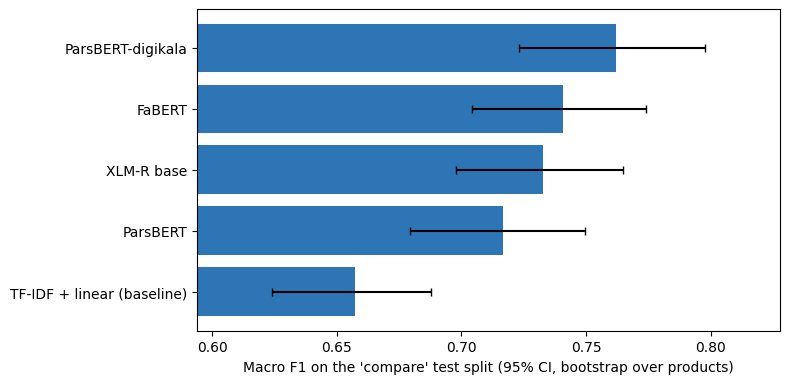

,model,f1_recommended,f1_not_recommended,f1_no_idea
0,ParsBERT-digikala,0.9424,0.8117,0.5322
1,ParsBERT,0.9153,0.7864,0.4488
2,FaBERT,0.9320,0.8000,0.4903
3,XLM-R base,0.9187,0.8160,0.4639
4,TF-IDF + linear (baseline),0.8938,0.7120,0.3659


best val Macro F1 = 0.7131; models within 0.005 of it: ['ParsBERT-digikala']

>>> RECOMMENDED: ParsBERT-digikala  (val=0.7131, test=0.7621, train=6.58 min)
NEXT: set MODE = 'final' and FINAL_MODEL_KEY = 'parsbert_digikala', then Run all (full data, 4 epochs, saves the model + predict_recommendation).
Remember: this is a 1-2 epoch screening on ~8000 comments; close calls (within the CI) are not real differences.


In [10]:
# ---- paired cluster bootstrap vs baseline (same test rows, same resampled products)
def paired_vs(run_a, run_b, n_boot=N_BOOT, seed=SEED):
    a = pd.read_parquet(run_a)[["id", "product_id", "y_true", "y_pred_final"]]
    b = pd.read_parquet(run_b)[["id", "y_pred_final"]].rename(columns={"y_pred_final": "pred_b"})
    m = a.merge(b, on="id", how="inner")
    if not (len(m) == len(a) == len(b)):
        return None
    yt = m["y_true"].map(L2I).values; pa = m["y_pred_final"].map(L2I).values; pb = m["pred_b"].map(L2I).values
    ca, cb = group_cms(yt, pa, m["product_id"].values), group_cms(yt, pb, m["product_id"].values)
    G = len(ca); rng = np.random.default_rng(seed); diffs = np.empty(n_boot)
    for i in range(n_boot):
        s = rng.integers(0, G, G)
        diffs[i] = macro_f1_from_cm(ca[s].sum(0)) - macro_f1_from_cm(cb[s].sum(0))
    return macro_f1_from_cm(ca.sum(0)) - macro_f1_from_cm(cb.sum(0)), np.percentile(diffs, [2.5, 97.5]), float((diffs <= 0).mean())

if bpred_path.exists():
    pr = []
    for r in runs:
        p = PRED_DIR / f"test_predictions_{r['run']}.parquet"
        if p.exists():
            res = paired_vs(p, bpred_path)
            if res is None:
                print(f"{r['run']}: baseline predictions do not cover the same test rows -> skipped"); continue
            d, ci_d, p_le0 = res
            verdict = "BETTER than baseline" if ci_d[0] > 0 else ("WORSE than baseline" if ci_d[1] < 0 else "no significant difference")
            pr.append({"run": r["run"], "Δ Macro F1 vs baseline": d, "95% CI lo": ci_d[0], "95% CI hi": ci_d[1], "P(Δ<=0)": p_le0, "verdict": verdict})
    if pr:
        paired = pd.DataFrame(pr); display(paired.round(4)); paired.to_csv(TF_DIR / f"paired_vs_baseline_{SUFFIX}.csv", index=False)
else:
    print("baseline predictions not found; skipped paired comparison")

# ---- plot
plot = comp.sort_values("test_macro_f1")
fig, ax = plt.subplots(figsize=(8, 0.55 * len(plot) + 1.2))
ax.barh(plot["model"], plot["test_macro_f1"], xerr=[plot["test_macro_f1"] - plot["ci_lo"], plot["ci_hi"] - plot["test_macro_f1"]], color="#2E75B6", capsize=3)
ax.set_xlabel(f"Macro F1 on the '{SPLIT_NAME}' test split (95% CI, bootstrap over products)")
ax.set_xlim(max(0.0, float(plot["ci_lo"].min()) - 0.03), min(1.0, float(plot["ci_hi"].max()) + 0.03))
plt.tight_layout(); plt.savefig(FIG_DIR / f"comparison_test_macro_f1_{SUFFIX}.png", dpi=150); plt.show()
display(comp[["model"] + [f"f1_{l}" for l in LABELS]].round(4))

# ---- selection rule
best_val = comp["val_macro_f1"].max()
close = comp[comp["val_macro_f1"] >= best_val - 0.005].copy()
close["cost"] = close["train_min"].fillna(0)
chosen = close.sort_values(["cost", "val_macro_f1"], ascending=[True, False]).iloc[0]
print(f"best val Macro F1 = {best_val:.4f}; models within 0.005 of it: {close['model'].tolist()}")
print(f"\n>>> RECOMMENDED: {chosen['model']}  (val={chosen['val_macro_f1']:.4f}, test={chosen['test_macro_f1']:.4f}, train={chosen['train_min']} min)")
if MODE == "compare":
    key_of = {v: k for k, v in NAMES.items()}
    if chosen["run"] == "baseline":
        print("The simple baseline is as good as the transformers on this screening run -> a very strong result for 'complexity must be justified'. "
              "You can still fine-tune the best transformer on the full data (MODE='final') to check whether more data/epochs change the picture.")
    else:
        print(f"NEXT: set MODE = 'final' and FINAL_MODEL_KEY = '{chosen['run'].replace('_lora', '')}', then Run all (full data, {FINAL_EPOCHS} epochs, saves the model + predict_recommendation).")
    print("Remember: this is a 1-2 epoch screening on ~8000 comments; close calls (within the CI) are not real differences.")